<a href="https://www.kaggle.com/code/kartikpradyumna92/housing-price-prediction?scriptVersionId=170705594" target="_blank"><img align="left" alt="Kaggle" title="Open in Kaggle" src="https://kaggle.com/static/images/open-in-kaggle.svg"></a>

# <p style="text-align: center;">Housing price prediction</p>
Objective: Predict the house price considering the metrics such as Area, bedrooms, bathrooms, stories and other metrics

Author: Karteek Pradyumna Bulusu

In [1]:
import pandas
import warnings
warnings.filterwarnings('ignore')
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

from sklearn import metrics
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

Import the dataset from Kaggle

In [2]:
def read_input():
    df = pandas.read_csv('/kaggle/input/housing-price-prediction/Housing.csv')
    print(f"Shape of the data: {df.shape}")
    print(df.head())
    
    # return Housing data in pandas DataFrame
    return df

In [3]:
import kagglehub
import os

# Download latest version
path = kagglehub.dataset_download("harishkumardatalab/housing-price-prediction")
files = os.listdir(path)
print("Path to dataset files:", path)

Path to dataset files: /Users/karteekpbulusu/.cache/kagglehub/datasets/harishkumardatalab/housing-price-prediction/versions/1


In [4]:
housing_df_list = []
for file in files:
    file_data = pandas.read_csv(path+'/'+file)
    housing_df_list.append(file_data)

housing_df = pandas.concat(housing_df_list, ignore_index=False)
housing_df.head(5)

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,yes,no,no,no,yes,2,yes,furnished
1,12250000,8960,4,4,4,yes,no,no,no,yes,3,no,furnished
2,12250000,9960,3,2,2,yes,no,yes,no,no,2,yes,semi-furnished
3,12215000,7500,4,2,2,yes,no,yes,no,yes,3,yes,furnished
4,11410000,7420,4,1,2,yes,yes,yes,no,yes,2,no,furnished


In [5]:
# housing_df = read_input()

# Exploratory Data Analysis
Function - eda_metrics(df)
return pandas DataFrame

<b>Description</b>: Perform basic data quality checks and describing the dataframe

In [6]:
def eda_metrics(df):
    # check if any of the fields have null values
    print(f'Boolean value showing if a field has null values\n\n {df.isnull().any()}')
    # Returns description of the dataframe- count, mean, standard deviation, min and max values of each field in the dataframe.
    print('\n----\nDescription of the dataframe\n')
    
    # return basic statistical details like percentile, mean, std, etc
    return df.describe()
    

In [7]:
eda_metrics(housing_df)

Boolean value showing if a field has null values

 price               False
area                False
bedrooms            False
bathrooms           False
stories             False
mainroad            False
guestroom           False
basement            False
hotwaterheating     False
airconditioning     False
parking             False
prefarea            False
furnishingstatus    False
dtype: bool

----
Description of the dataframe



,price,area,bedrooms,bathrooms,stories,parking
count,5.450000e+02,545.000000,545.000000,545.000000,545.000000,545.000000
mean,4.766729e+06,5150.541284,2.965138,1.286239,1.805505,0.693578
std,1.870440e+06,2170.141023,0.738064,0.502470,0.867492,0.861586
min,1.750000e+06,1650.000000,1.000000,1.000000,1.000000,0.000000
25%,3.430000e+06,3600.000000,2.000000,1.000000,1.000000,0.000000
50%,4.340000e+06,4600.000000,3.000000,1.000000,2.000000,0.000000
75%,5.740000e+06,6360.000000,3.000000,2.000000,2.000000,1.000000
max,1.330000e+07,16200.000000,6.000000,4.000000,4.000000,3.000000


#### Re-arranging fields

In [8]:
housing_df['house_id'] = housing_df.index + 1
print(housing_df.columns)

Index(['price', 'area', 'bedrooms', 'bathrooms', 'stories', 'mainroad',
       'guestroom', 'basement', 'hotwaterheating', 'airconditioning',
       'parking', 'prefarea', 'furnishingstatus', 'house_id'],
      dtype='str')


In [9]:
housing_df = housing_df[[ 'house_id', 'area', 'bedrooms', 'bathrooms', 'stories', 'mainroad',
       'guestroom', 'basement', 'hotwaterheating', 'airconditioning',
       'parking', 'prefarea', 'furnishingstatus', 'price']]

# Data Cleaning
<br>
Convert all labelled values into categorical values in order to perform correlation analysis and prediction analysis.
Only then those values will have a statistical signifance and can be used as a feature.

Convert labelled values to categorical values
Change:
Yes = 1<br>
No = 0

Create three columns - one for each of the categories part of furnishingstatus column with same name as values.

In [10]:
def data_cleaning(df):

    df[['mainroad', 'guestroom', 'basement', 'hotwaterheating', 'airconditioning', 'prefarea']] = df[['mainroad', 'guestroom', 'basement', 'hotwaterheating', 'airconditioning', 'prefarea']].replace({'yes':1, 'no':0})
    # assigning values to each categorical value instead of creating new boolean column for each value to reduce dimension
    # Giving more weight (value = 3) from furnished and 1 to unfurnished
    df['furnishingstatus'] = df['furnishingstatus'].replace({'furnished':3, 'semi-furnished':2, 'unfurnished':1})

    # replace() leaves these columns as object dtype; cast to int so correlation and VIF treat them as numeric
    encoded_columns = ['mainroad', 'guestroom', 'basement', 'hotwaterheating', 'airconditioning', 'prefarea', 'furnishingstatus']
    df[encoded_columns] = df[encoded_columns].astype(int)

    # Return cleaned data without any categorical values.
    return df

In [11]:
housing_df = data_cleaning(housing_df)

### Dimension
12 Features and 1 Target value
Note - Ignorning house_id from feature list since it's just an identifier.
545 rows

In [12]:
print(housing_df.shape)
housing_df.head()

(545, 14)


,house_id,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus,price
0,1,7420,4,2,3,1,0,0,0,1,2,1,3,13300000
1,2,8960,4,4,4,1,0,0,0,1,3,0,3,12250000
2,3,9960,3,2,2,1,0,1,0,0,2,1,2,12250000
3,4,7500,4,2,2,1,0,1,0,1,3,1,3,12215000
4,5,7420,4,1,2,1,1,1,0,1,2,0,3,11410000


# Correlation Matrix
Correlation between all the features and the Target

In [13]:
# Removing house_id from the correlation analysis

def correlation_matrix(correlation_ip,threshold = -1.0):
    corr = correlation_ip.corr()
    ax = sns.heatmap(
        corr, 
        vmin=-1, vmax=1, center=0,
        cmap=sns.diverging_palette(20, 220, n=200),
        square=True
    )
    ax.set_xticklabels(
        ax.get_xticklabels(),
        rotation=45,
        horizontalalignment='right'
    );
    
    correlation_score = correlation_ip.corr(numeric_only=True)
    
    # return correclation matrix of the dataframe
    return correlation_score[correlation_score > threshold]

,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus,price
area,1.000000,0.151858,0.193820,0.083996,0.288874,0.140297,0.047417,-0.009229,0.222393,0.352980,0.234779,0.171445,0.535997
bedrooms,0.151858,1.000000,0.373930,0.408564,-0.012033,0.080549,0.097312,0.046049,0.160603,0.139270,0.079023,0.123244,0.366494
bathrooms,0.193820,0.373930,1.000000,0.326165,0.042398,0.126469,0.102106,0.067159,0.186915,0.177496,0.063472,0.143559,0.517545
stories,0.083996,0.408564,0.326165,1.000000,0.121706,0.043538,-0.172394,0.018847,0.293602,0.045547,0.044425,0.104672,0.420712
mainroad,0.288874,-0.012033,0.042398,0.121706,1.000000,0.092337,0.044002,-0.011781,0.105423,0.204433,0.199876,0.156726,0.296898
guestroom,0.140297,0.080549,0.126469,0.043538,0.092337,1.000000,0.372066,-0.010308,0.138179,0.037466,0.160897,0.118328,0.255517
basement,0.047417,0.097312,0.102106,-0.172394,0.044002,0.372066,1.000000,0.004385,0.047341,0.051497,0.228083,0.112831,0.187057
hotwaterheating,-0.009229,0.046049,0.067159,0.018847,-0.011781,-0.010308,0.004385,1.000000,-0.130023,0.067864,-0.059411,0.031628,0.093073
airconditioning,0.222393,0.160603,0.186915,0.293602,0.105423,0.138179,0.047341,-0.130023,1.000000,0.159173,0.117382,0.150477,0.452954
parking,0.352980,0.139270,0.177496,0.045547,0.204433,0.037466,0.051497,0.067864,0.159173,1.000000,0.091627,0.177539,0.384394


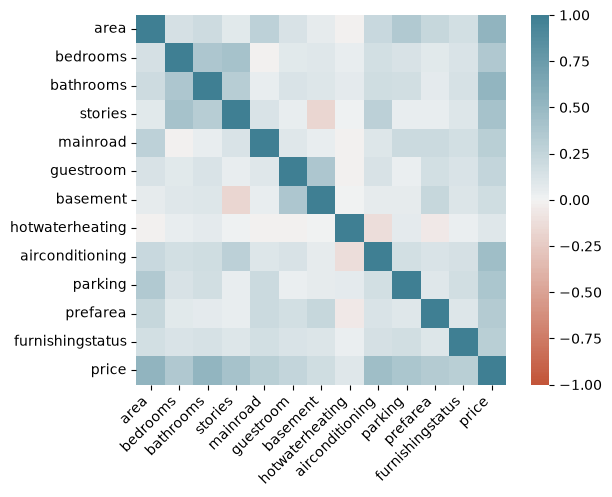

In [14]:
correlation_ip = housing_df[['area', 'bedrooms', 'bathrooms', 'stories', 'mainroad', 'guestroom', 'basement',
                         'hotwaterheating', 'airconditioning','parking', 'prefarea', 'furnishingstatus','price']]
correlation_matrix(correlation_ip)

**Correlation Notes**

Price is most correlated with area (0.54), bathrooms (0.52), airconditioning (0.45), stories (0.42), parking (0.38) and bedrooms (0.37).
<br>furnishingstatus is encoded furnished = 3, semi-furnished = 2, unfurnished = 1, and its correlation with price is positive (0.30). Furnished houses sell for more.
<br>The features are only weakly correlated with each other. The largest correlation between two features is 0.41 (bedrooms and stories).

Removing `hotwaterheating` from features since correlation of that to price is very low = 0.09.

In [15]:
housing_df_postcorr = housing_df[['house_id','area', 'bedrooms', 'bathrooms', 'stories', 'mainroad', 'guestroom', 'basement',
                          'airconditioning','parking', 'prefarea', 'furnishingstatus','price']].copy()

---

# Variance Inflation Factor
This is to test the multicollinearity of the features (predictors)

Underdstanding the result:<br>
VIF starts at 1 and has no upper limit<br>
VIF = 1, no correlation between the independent variable and the other variables<br>
VIF exceeding 5 or 10 indicates high multicollinearity between this independent variable and the others<br>

#### reference- https://www.analyticsvidhya.com/blog/2020/03/what-is-multicollinearity/

In [16]:
# import
from statsmodels.stats.outliers_influence import variance_inflation_factor

In [17]:
import statsmodels.api as sm

# X is features list in a pandas dataframe format
# Returns dataframe vif  with VIF score.
def calc_vif(X):
    # VIF assumes the regression includes an intercept. Without one, VIF is inflated for every
    # feature whose mean is far from zero, so add the constant explicitly and skip it in the output.
    X_with_const = sm.add_constant(X.astype(float))

    # Calculating VIF
    vif = pandas.DataFrame()
    vif["variables"] = X.columns
    vif["VIF"] = [variance_inflation_factor(X_with_const.values, i + 1) for i in range(X.shape[1])]

    # Return VIF score for each feature
    return(vif)

In [18]:
X = housing_df_postcorr[['area', 'bedrooms', 'bathrooms', 'stories', 'mainroad', 'guestroom', 'basement',
                          'airconditioning','parking', 'prefarea', 'furnishingstatus']]
print(calc_vif(X))

           variables       VIF
0               area  1.325096
1           bedrooms  1.366970
2          bathrooms  1.282542
3            stories  1.476529
4           mainroad  1.172565
5          guestroom  1.212687
6           basement  1.320470
7    airconditioning  1.178883
8            parking  1.204913
9           prefarea  1.145106
10  furnishingstatus  1.094447


### VIF First pass notes:
Every feature has a VIF between about 1.1 and 1.5, well below the usual 5 to 10 threshold for high multicollinearity. The largest pairwise correlation between two features is about 0.41 (bedrooms and stories). **Multicollinearity in this dataset is mild.**

An earlier version of this notebook reported much higher values:

                       variables    VIF
           0               area  8.373
           1           bedrooms 16.268
           2          bathrooms  9.468
           3            stories  7.882
           4           mainroad  7.144
           5          guestroom  1.467
           6           basement  2.027
           7    airconditioning  1.703
           8            parking  1.937
           9           prefarea  1.482
           10  furnishingstatus  7.394

Those values come from computing VIF **without an intercept**, which measures how far each feature is from zero rather than how well the other features predict it. With the intercept included (as `calc_vif` now does), they drop to the values above.

The next section still tries combining several features into one composite ratio, as an experiment in reducing the number of features.

### Removing Multicollinearity in the data
New field:
area_and_furnishingstatus_and_mainroad_to_bed_and_bath_stories_ratio = (area*furnishingstatus*mainroad)/(bedroom + bathroom + stories)

Remove area, bedrooms, bathrooms, mainroad, furnishingstatus, stories

In [19]:
# housing_df['bedroom_to_bath_ratio'] = round(housing_df['bedrooms']/housing_df['bathrooms'],3)
housing_df_postcorr['area_and_furnishingstatus_and_mainroad_to_bed_and_bath_stories_ratio'] = round(((housing_df_postcorr['area'] * housing_df_postcorr['furnishingstatus'] * (housing_df['mainroad']+1))/ (housing_df_postcorr['bedrooms']+housing_df_postcorr['bathrooms']+housing_df_postcorr['stories'])),3)
housing_df_postcorr_vif1 = housing_df_postcorr[['house_id', 'area_and_furnishingstatus_and_mainroad_to_bed_and_bath_stories_ratio', 'guestroom', 'basement',
                          'airconditioning','parking', 'prefarea', 'price']]
housing_df_postcorr_vif1.head()

,house_id,area_and_furnishingstatus_and_mainroad_to_bed_and_bath_stories_ratio,guestroom,basement,airconditioning,parking,prefarea,price
0,1,4946.667,0,0,1,2,1,13300000
1,2,4480.000,0,0,1,3,0,12250000
2,3,5691.429,0,1,0,2,1,12250000
3,4,5625.000,0,1,1,3,1,12215000
4,5,6360.000,1,1,1,2,0,11410000


### See if VIF improved

In [20]:
X = housing_df_postcorr_vif1[['area_and_furnishingstatus_and_mainroad_to_bed_and_bath_stories_ratio', 'guestroom', 'basement',
                          'airconditioning','parking', 'prefarea']]
print(calc_vif(X))

                                           variables       VIF
0  area_and_furnishingstatus_and_mainroad_to_bed_...  1.143910
1                                          guestroom  1.189607
2                                           basement  1.206031
3                                    airconditioning  1.056073
4                                            parking  1.117848
5                                           prefarea  1.099793


Using VIF, we unified lot of features into one and hence reduced the features list from 11 to 6.

We fit linear regression on two versions of this:
1. the composite ratio on its own (1 feature)
2. the full feature set left after the VIF step (6 features)

In [21]:
housing_df_postcorr_vif1.head()

,house_id,area_and_furnishingstatus_and_mainroad_to_bed_and_bath_stories_ratio,guestroom,basement,airconditioning,parking,prefarea,price
0,1,4946.667,0,0,1,2,1,13300000
1,2,4480.000,0,0,1,3,0,12250000
2,3,5691.429,0,1,0,2,1,12250000
3,4,5625.000,0,1,1,3,1,12215000
4,5,6360.000,1,1,1,2,0,11410000


#### Split Features and Target

In [22]:
# Splitting dataset to Feature and Target
# (1) the composite ratio on its own
features = housing_df_postcorr_vif1[['area_and_furnishingstatus_and_mainroad_to_bed_and_bath_stories_ratio']]
features = features.values.reshape(-1, 1)

# (2) the full feature set left after the VIF step
vif_features = housing_df_postcorr_vif1[['area_and_furnishingstatus_and_mainroad_to_bed_and_bath_stories_ratio',
       'guestroom', 'basement', 'airconditioning', 'parking', 'prefarea']]

target = housing_df_postcorr.price
print(f" Shape of features: {features.shape}")
print(f" Shape of VIF features: {vif_features.shape}")
print(f" Shape of target: {target.shape}")

 Shape of features: (545, 1)
 Shape of VIF features: (545, 6)
 Shape of target: (545,)


In [23]:
from sklearn.model_selection import train_test_split, KFold, cross_val_score

# 5-fold cross validation on the training data, shared by every model below
kf = KFold(n_splits=5, shuffle=True, random_state=42)

### Train and Test Split
#### Function - train_test_splt(features, target)
return X_train, X_test, y_train, y_test <br>
<b>Description:</b>
Creating function to take the features and target value and split the data into train and test data and return them. <br>Creating this function also increase re-usability and flexibility while experimenting with multiple models

In [24]:
def train_test_splt(features, target):
    X_train, X_test, y_train, y_test = train_test_split(features,target , 
                                       random_state=104,  
                                       test_size=0.15,
                                       shuffle=True)
    
    # return Train and test data split for Feature and Target in pandas DataFrame format
    return X_train, X_test, y_train, y_test

### Function - Train_test_details(X_train, X_test, y_train, y_test)
print shape of Train and test features and Target <br>
<b>Description:</b>
Creating function to return the shape of all dataframes and to increase re-usability and flexibility while experimenting with multiple models

In [25]:
def Train_test_details(X_train, X_test, y_train, y_test):
    print("Training feature",X_train.shape)
    print("Test feature",X_test.shape)
    print("Training target",y_train.shape)
    print("Test target",y_test.shape)

### Function - training_model(X_train, X_test, y_train, y_test, model)
returns built model <br>
<b>Description:</b>
Creating function to train the model and provide model score in order to increase re-usability and flexibility while experimenting with multiple models

In [26]:
def training_model(X_train, X_test, y_train, y_test, model):
    model.fit(X_train, y_train)
    # Use score method to get accuracy of model
    train_score = model.score(X_train, y_train)
    test_score = model.score(X_test, y_test)
    print(f'Training score : {train_score}')
    print(f'Test score : {test_score}')
    
    # return the built model
    return model

### Function - predictions_phase(df, model)
returns predictions in pandas DataFrame <br>
<b>Description:</b>
Creating function to perform predcitions and return predicted values in order to increase re-usability and flexibility while experimenting with multiple models

In [27]:
def predictions_phase(df, model):
    predictions = model.predict(df)
    
    # return the predictions in pandas DataFrame
    return predictions

### Function - prediction_dataframes(train_predictions,y_train,test_predictions, y_test)
returns two pandas dataframes: 1 with y_test and y_predictions (test_predictions); second with y_train and y_predictions (train_predictions)

<b>Description</b>: function to currate dataframe to see actual data and predictions side by side. Creating this function increases re-usability and flexibility while experimenting with multiple models

In [28]:
def prediction_dataframes(train_predictions,y_train,test_predictions, y_test):
    final_test_predictions = [round(x,6) for x in test_predictions]
    final_train_predictions = [round(x,6) for x in train_predictions]
    
    # Dataframe for test predictions
    test_predictions_andy_test = pandas.DataFrame()
    test_predictions_andy_test['y_test'] = y_test
    test_predictions_andy_test['test_predictions'] = final_test_predictions

    # Dataframe for train predictions
    train_predictions_andy_train = pandas.DataFrame()
    train_predictions_andy_train['y_train'] = y_train
    train_predictions_andy_train['train_predictions'] = final_train_predictions
    
    # return the values in pandas DataFrame
    return test_predictions_andy_test, train_predictions_andy_train

### Function - error_analysis(target, predictions)
returns MAE, MSE and r2 score

<b>Description</b>: function to perform error analysis based on the actual data and predictions. Creating this function increases re-usability and flexibility while experimenting with multiple models

In [29]:
def error_analysis(target, predictions):
    mae = mean_absolute_error(target, predictions)
    mse = mean_squared_error(target, predictions)
    r2 = r2_score(target, predictions)
    
    # Return error metrics
    return f'MAE : {mae};\t MSE : {mse};\t r2 : {r2}'

### Function - record_results(name, model, X_train, X_test, y_train, y_test, cv_r2, best_alpha)
Stores the metrics for the final comparison table

<b>Description</b>: every model is evaluated on the same test rows (`train_test_splt`, random_state=104, test_size=0.15). CV R² is the mean R² over 5 folds of the training data only, so it is never influenced by the test rows.

In [30]:
# Keyed by model name, so re-running a cell overwrites its row instead of adding a duplicate
results = {}

def record_results(name, model, X_train, X_test, y_train, y_test, cv_r2, best_alpha='-'):
    test_predictions = model.predict(X_test)
    # For a Pipeline, the coefficients live on the final step
    estimator = model.named_steps['model'] if hasattr(model, 'named_steps') else model
    results[name] = {
        'Features': X_train.shape[1],
        'Best alpha': best_alpha,
        'CV R2 (train folds)': cv_r2,
        'Test R2': r2_score(y_test, test_predictions),
        'Test MAE': mean_absolute_error(y_test, test_predictions),
        'Non-zero coefs': f"{int(np.sum(estimator.coef_ != 0))} of {X_train.shape[1]}",
    }

---

# LinearRegression on feature prepared from Variance inflation Factor process
Predicting using Linear Regression model
The data considered is feature identified from Variance inflation Factor process

Uses the same `train_test_splt` helper (random_state=104, test_size=0.15) as every other model, so all test scores are measured on the same houses.

In [31]:
X_train, X_test, y_train, y_test = train_test_splt(features, target)

In [32]:
Train_test_details(X_train, X_test, y_train, y_test)

Training feature (463, 1)
Test feature (82, 1)
Training target (463,)
Test target (82,)


In [33]:
from sklearn.linear_model import LinearRegression

In [34]:
model = LinearRegression()
LinearRegr = training_model(X_train, X_test, y_train, y_test, model)

Training score : 0.10432734033803581
Test score : 0.0681713714203418


In [35]:
train_predictions = predictions_phase(X_train, LinearRegr)
test_predictions = predictions_phase(X_test, LinearRegr)

In [36]:
pandas.set_option('display.float_format', lambda x: '%.3f' % x)

In [37]:
test_predictions_andy_test, train_predictions_andy_train = prediction_dataframes(train_predictions,y_train,test_predictions, y_test)

In [38]:
print(f'Train data prediction score \n {error_analysis(y_train, train_predictions)}')
print(f'Test data prediction score \n {error_analysis(y_test, test_predictions)}')

Train data prediction score 
 MAE : 1299732.4548979357;	 MSE : 3011422108038.5054;	 r2 : 0.10432734033803581
Test data prediction score 
 MAE : 1543055.0431330001;	 MSE : 3878842649347.5815;	 r2 : 0.0681713714203418


In [39]:
vif_composite_cv_r2 = cross_val_score(LinearRegression(), X_train, y_train, cv=kf, scoring='r2').mean()
print(f'CV R2 (5 folds on training data) : {vif_composite_cv_r2}')
record_results('Linear regression on the VIF composite', LinearRegr, X_train, X_test, y_train, y_test, vif_composite_cv_r2)

CV R2 (5 folds on training data) : 0.08508445762461467


#### plot train and test predictions

In [40]:
def plot_predictions(X_train, y_train, train_predictions, X_test, y_test, test_predictions):
    plt.figure(figsize=(16, 8))

    # train data
    plt.subplot(121)
    plt.scatter(X_train, y_train)
    plt.yscale('log')
    plt.title("Train data")
    # for i, degree in enumerate(degrees):    
    plt.scatter(X_train, train_predictions, s=15)
    plt.legend(loc='upper left')

    # test data
    plt.subplot(122)
    plt.scatter(X_test, y_test)
    plt.yscale('log')
    plt.title("Test data")
    # for i, degree in enumerate(degrees):    
    plt.scatter(X_test, test_predictions)
    plt.legend(loc='upper left')

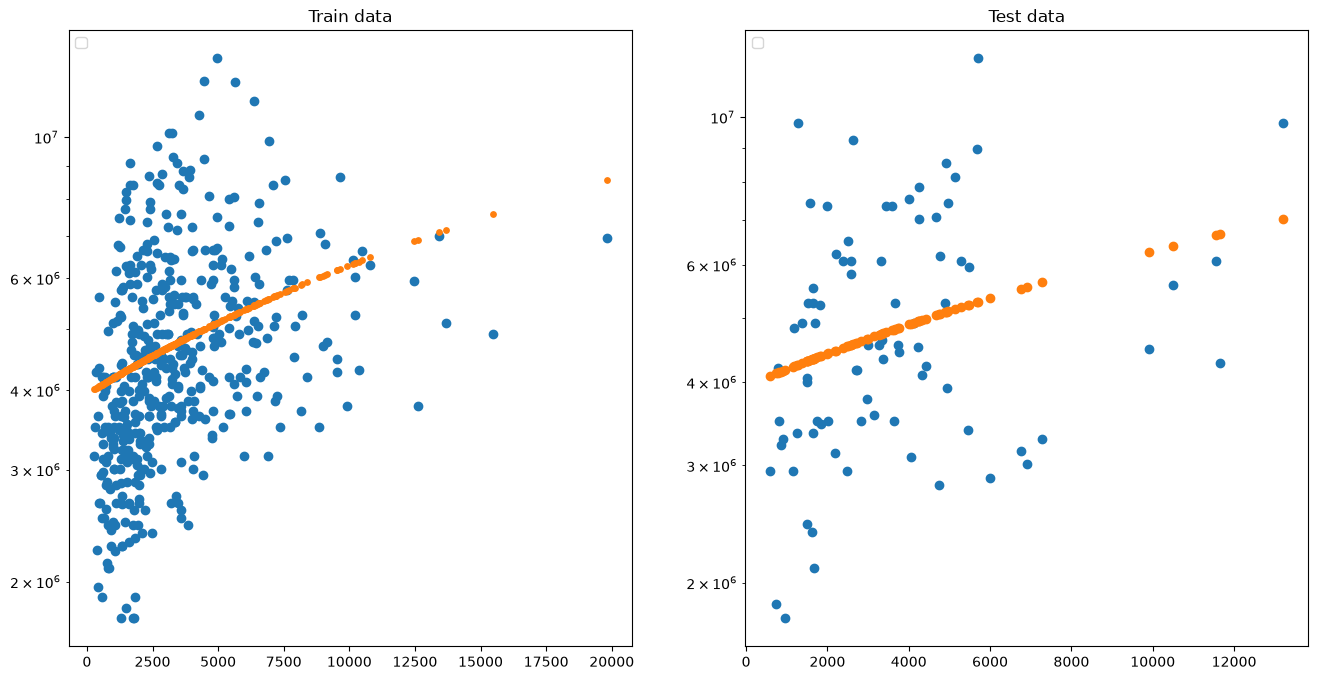

In [41]:
plot_predictions(X_train, y_train, train_predictions, X_test, y_test, test_predictions)

### Conclusion Notes on Variance inflation Factor and LinearRegression (composite ratio only)
r2 of Training data : 0.104<br>
r2 of Test data : 0.068<br>
CV r2 (5 folds on training data) : 0.085
<br>
Tried Variance Inflation Factor and unified multiple fields to reduce the correlation between the fields. The problem is identifying the appropriate way to unify multiple fields to capture the importance of multiple fields into one and drop those individual fields.
<br>The predictions are very weak and almost neglible. This concludes that it is tough and was incorrect way to combine the features together in order to reduce the multicollinearity.

# LinearRegression on the full VIF feature set
The composite ratio alone drops guestroom, basement, airconditioning, parking and prefarea, even though the VIF step kept them. Fitting on all 6 features left after the VIF step gives a fairer picture of the VIF approach.

In [42]:
X_train, X_test, y_train, y_test = train_test_splt(vif_features, target)
Train_test_details(X_train, X_test, y_train, y_test)

Training feature (463, 6)
Test feature (82, 6)
Training target (463,)
Test target (82,)


In [43]:
model = LinearRegression()
LinearRegr_vif_features = training_model(X_train, X_test, y_train, y_test, model)

Training score : 0.39892755436007377
Test score : 0.4591728039867272


In [44]:
train_predictions = predictions_phase(X_train, LinearRegr_vif_features)
test_predictions = predictions_phase(X_test, LinearRegr_vif_features)
print(f'Train data prediction score \n {error_analysis(y_train, train_predictions)}')
print(f'Test data prediction score \n {error_analysis(y_test, test_predictions)}')

Train data prediction score 
 MAE : 1069825.924337188;	 MSE : 2020920066953.9136;	 r2 : 0.39892755436007377
Test data prediction score 
 MAE : 1096865.576105771;	 MSE : 2251254715173.2163;	 r2 : 0.4591728039867272


In [45]:
vif_features_cv_r2 = cross_val_score(LinearRegression(), X_train, y_train, cv=kf, scoring='r2').mean()
print(f'CV R2 (5 folds on training data) : {vif_features_cv_r2}')
record_results('Linear regression on the VIF feature set', LinearRegr_vif_features, X_train, X_test, y_train, y_test, vif_features_cv_r2)

CV R2 (5 folds on training data) : 0.3653847197850113


### Conclusion Notes on the full VIF feature set
r2 of Training data : 0.399<br>
r2 of Test data : 0.459<br>
CV r2 (5 folds on training data) : 0.365
<br>
Keeping the other 5 VIF features lifts test r2 from 0.068 to 0.459, but it is still well below the models on the 11 original features (next sections). Merging area, bedrooms, bathrooms, stories, mainroad and furnishingstatus into one ratio throws information away, and since VIF was already low there was little multicollinearity to remove in the first place.

---

# MinMaxScaler
Hypothesis - Scaling down the features and target to [0.1] range will help with bias variance trade off and result in better model fit and predictions<br>
Transform the dataframe to [0,1] range

In [46]:
from sklearn.preprocessing import MinMaxScaler

### Function - minmax_scale(df)
return scaled dataframe in pandas DataFrame format<br>

<b>Description</b>: Scaling the dataset in [0,1] range and return the scaled dataframe.

In [47]:
def minmax_scale(df):
    df_columns = df.columns
    scaler = MinMaxScaler()
    df = scaler.fit_transform(df)

    df = pandas.DataFrame(df)
    df.columns = df_columns
    
    # return scaled data in pandas DataFrame
    return df

In [48]:
df1 = housing_df_postcorr_vif1[['area_and_furnishingstatus_and_mainroad_to_bed_and_bath_stories_ratio', 'price']]
df1.head()

,area_and_furnishingstatus_and_mainroad_to_bed_and_bath_stories_ratio,price
0,4946.667,13300000
1,4480.000,12250000
2,5691.429,12250000
3,5625.000,12215000
4,6360.000,11410000


In [49]:
df1_scaled = minmax_scale(df1)
df1_scaled.head()

,area_and_furnishingstatus_and_mainroad_to_bed_and_bath_stories_ratio,price
0,0.239,1.000
1,0.215,0.909
2,0.277,0.909
3,0.274,0.906
4,0.312,0.836


#### Split Features and Target

In [50]:
scaled_features = df1_scaled[['area_and_furnishingstatus_and_mainroad_to_bed_and_bath_stories_ratio']] 
scaled_features = scaled_features.values.reshape(-1, 1)
target = df1_scaled.price
print(scaled_features.shape)
print(target.shape)

(545, 1)
(545,)


#### Train and Split the scaled dataframe

In [51]:
X_train, X_test, y_train, y_test = train_test_splt(scaled_features, target)
Train_test_details(X_train, X_test, y_train, y_test)

Training feature (463, 1)
Test feature (82, 1)
Training target (463,)
Test target (82,)


#### Re-building the model with Scaled dataframe

In [52]:
model = LinearRegression()
LinearRegr = training_model(X_train, X_test, y_train, y_test, model)

Training score : 0.10432734033803603
Test score : 0.0681713714203418


In [53]:
train_predictions = predictions_phase(X_train, LinearRegr)
test_predictions = predictions_phase(X_test, LinearRegr)

#### Combined prediction values dataframe

In [54]:
test_predictions_andy_test, train_predictions_andy_train = prediction_dataframes(train_predictions,y_train,test_predictions, y_test)

#### Error analysis

In [55]:
print(f'Train data prediction score \n {error_analysis(y_train, train_predictions)}')
print(f'Test data prediction score \n {error_analysis(y_test, test_predictions)}')

Train data prediction score 
 MAE : 0.11253094847601178;	 MSE : 0.022573955570836416;	 r2 : 0.10432734033803603
Test data prediction score 
 MAE : 0.13359783923229437;	 MSE : 0.029076236572384933;	 r2 : 0.0681713714203418


#### Plotting predictions from the scaled dataset

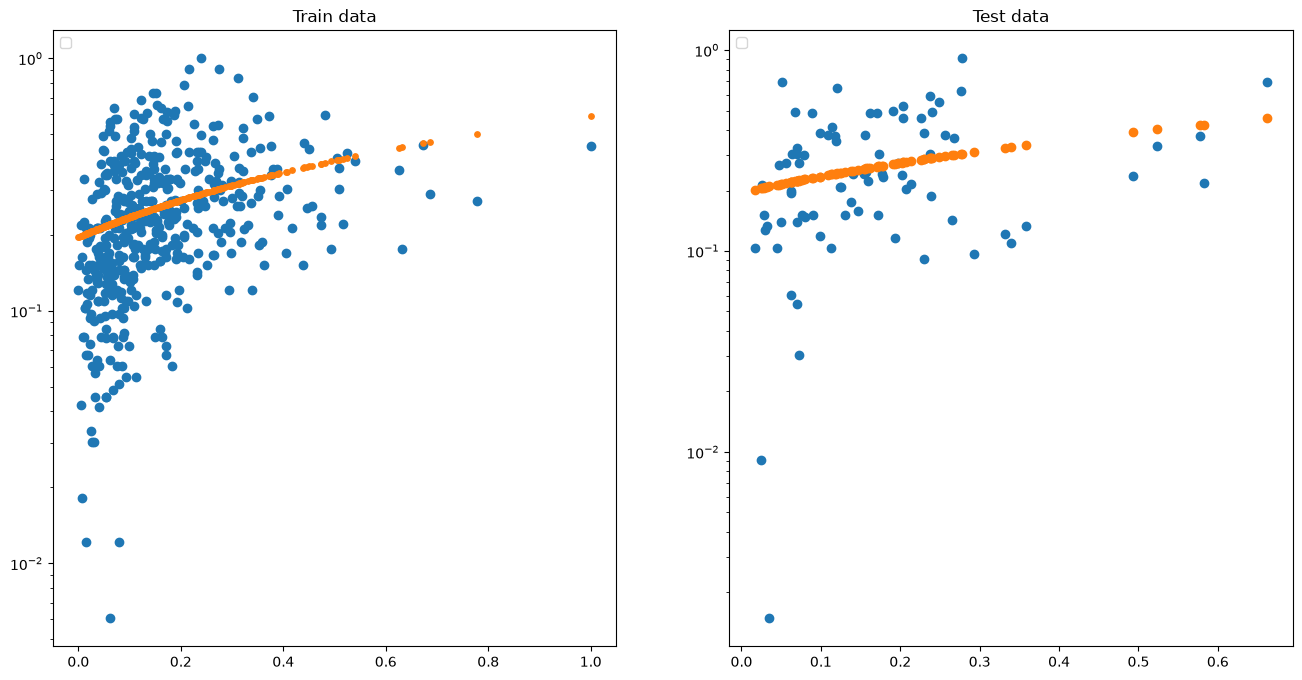

In [56]:
plot_predictions(X_train, y_train, train_predictions, X_test, y_test, test_predictions)

### Conclusion notes on MinMaxScaler and LinearRegression

r2 of Training data : 0.104<br>
r2 of Test data : 0.068<br>
These are exactly the same as the unscaled model above, which is expected. Linear regression is not affected by rescaling the features or the target: the coefficients rescale to compensate, and r2 stays the same. This hypothesis is not proved right and the experiment of using MinMaxScaler to acheive better predictions ends.
<br>Scaling does matter for models that penalize coefficient size, like Ridge and Lasso. That is why the next section scales features inside a Pipeline.

------

# Using Lasso and Ridge Regression on all the original features

The VIF approach lost too much information, so we go back to all 11 original features. VIF showed multicollinearity among them is mild, so regularization may not add much, but we test it properly:

1. **Linear regression baseline** on the same 11 features, so there is something to compare against.
2. **Split first, tune second**: GridSearchCV only sees the training data, so the test rows never influence which alpha is chosen.
3. **Scale inside a Pipeline**: Ridge and Lasso penalize coefficient size, so features must be on the same scale (area is in the thousands, bedrooms 1 to 6). `StandardScaler` inside the Pipeline learns the scaling from the training folds only.
4. **Wide log-scale alpha grids**, so GridSearchCV has real choices to pick from.

In [57]:
from sklearn import linear_model
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

In [58]:
# Using all the features as provided in the original dataset
features = housing_df_postcorr[['area', 'bedrooms', 'bathrooms', 'stories', 'mainroad',
       'guestroom', 'basement', 'airconditioning', 'parking', 'prefarea',
       'furnishingstatus']]
# features = features.values.reshape(-1, 1)
target = housing_df_postcorr.price
print(f"Shape of the features: {features.shape}")
print(features.head(5))

print(f"\nShape of the Target: {target.shape}")
print(target.head(5))


Shape of the features: (545, 11)
   area  bedrooms  bathrooms  stories  mainroad  guestroom  basement  \
0  7420         4          2        3         1          0         0   
1  8960         4          4        4         1          0         0   
2  9960         3          2        2         1          0         1   
3  7500         4          2        2         1          0         1   
4  7420         4          1        2         1          1         1   

   airconditioning  parking  prefarea  furnishingstatus  
0                1        2         1                 3  
1                1        3         0                 3  
2                0        2         1                 2  
3                1        3         1                 3  
4                1        2         0                 3  

Shape of the Target: (545,)
0    13300000
1    12250000
2    12250000
3    12215000
4    11410000
Name: price, dtype: int64


#### Train and test split
Split once, before any tuning. Every model below uses these same training and test rows.

In [59]:
X_train, X_test, y_train, y_test = train_test_splt(features, target)
Train_test_details(X_train, X_test, y_train, y_test)

Training feature (463, 11)
Test feature (82, 11)
Training target (463,)
Test target (82,)


# Linear regression baseline (all 11 features)
Plain linear regression in the same Pipeline and split. This is the baseline Ridge and Lasso need to beat.

In [60]:
linreg_pipe = Pipeline([("scaler", StandardScaler()), ("model", LinearRegression())])

linreg_cv_r2 = cross_val_score(linreg_pipe, X_train, y_train, cv=kf, scoring='r2').mean()
linreg_model = training_model(X_train, X_test, y_train, y_test, linreg_pipe)
print(f'CV R2 (5 folds on training data) : {linreg_cv_r2}')

Training score : 0.6599646461720708
Test score : 0.7092047045822688
CV R2 (5 folds on training data) : 0.618131434030853


In [61]:
train_predictions = predictions_phase(X_train, linreg_model)
test_predictions = predictions_phase(X_test, linreg_model)
print(f'Train data prediction score \n {error_analysis(y_train, train_predictions)}')
print(f'Test data prediction score \n {error_analysis(y_test, test_predictions)}')
record_results('Linear regression', linreg_model, X_train, X_test, y_train, y_test, linreg_cv_r2)

Train data prediction score 
 MAE : 781456.1182625087;	 MSE : 1143263636537.243;	 r2 : 0.6599646461720708
Test data prediction score 
 MAE : 760710.2090229564;	 MSE : 1210468491202.2976;	 r2 : 0.7092047045822688


# GridSearchCV and Lasso regression
Using GridSearchCV to identify best value for alpha (hyperparameter) for Lasso regression.<br>
Use it to build and fit the model and perform predictions.

Price is in the millions, so the Lasso penalty only starts to matter at large alpha values. The grid runs from 10² to 10⁷ on a log scale.

In [62]:
# Wide log-scale grid. Price is in the millions, so Lasso needs large alpha before the penalty has any effect
params = {"model__alpha": np.logspace(2, 7, 26)}

# Scaling inside the Pipeline is learned from the training folds only
lasso_pipe = Pipeline([("scaler", StandardScaler()), ("model", linear_model.Lasso(max_iter=50000))])

# GridSearchCV with model, params and folds, fit on the training data only
lasso_gridsearch = GridSearchCV(lasso_pipe, param_grid=params, cv=kf, scoring='r2')
lasso_gridsearch.fit(X_train, y_train)

best_alpha = lasso_gridsearch.best_params_['model__alpha']
print(f"Best Params for alpha is {best_alpha}")
print(f"CV R2 at best alpha (5 folds on training data) : {lasso_gridsearch.best_score_}")

Best Params for alpha is 15848.93192461114
CV R2 at best alpha (5 folds on training data) : 0.6186043047513288


In [63]:
# GridSearchCV refits the pipeline with the best alpha on the whole training set
lasso_model = lasso_gridsearch.best_estimator_

In [64]:
print(f"Trained model score : {lasso_model.score(X_train, y_train)}")
print(f"Adjusted R squared : {1 - (1-lasso_model.score(X_train, y_train))*(len(y_train)-1)/(len(y_train)-X_train.shape[1]-1)}")

Trained model score : 0.6596126803450878
Adjusted R squared : 0.6513105505974071


In [65]:
lasso_model_coef = [float(x) for x in np.abs(lasso_model.named_steps['model'].coef_)]
lasso_model_coef_array = np.asarray(lasso_model_coef)
feature_names = features.columns.tolist()

#### Features and its estimated coefficients based on Lasso Regression
The features are standardized, so each coefficient is the change in price for a 1 standard deviation change in that feature. That makes the magnitudes comparable across features.

In [66]:
coefficients_df = pandas.DataFrame()
coefficients_df['features'] = feature_names
coefficients_df['coefficients'] = lasso_model_coef
coefficients_df

,features,coefficients
0,area,511814.782
1,bedrooms,100618.085
2,bathrooms,501183.213
3,stories,350869.062
4,mainroad,134178.071
5,guestroom,113959.580
6,basement,161467.147
7,airconditioning,373096.882
8,parking,206331.455
9,prefarea,256846.742


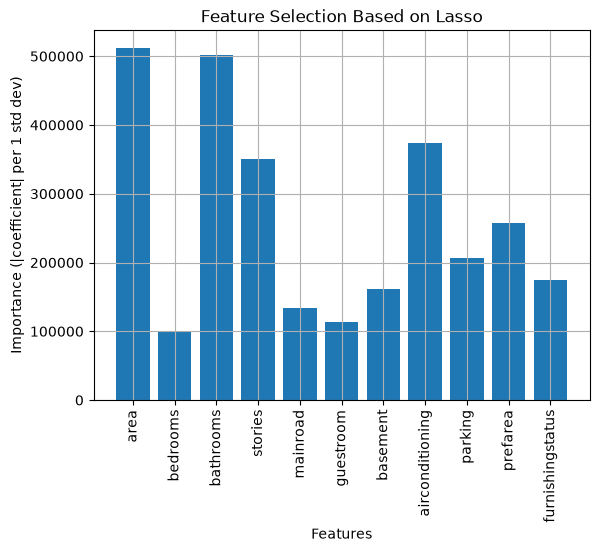

In [67]:
# plotting the Column Names and Importance of Columns.
plt.bar(feature_names, lasso_model_coef_array)
plt.xticks(rotation=90)
plt.grid()
plt.title("Feature Selection Based on Lasso")
plt.xlabel("Features")
plt.ylabel("Importance (|coefficient| per 1 std dev)")
plt.show()

Feature selection<br>
Selecting features with importance > 200000 (on the standardized scale)

In [68]:
# Subsetting the features which has more than 200000 importance.
feature_subset = np.array(feature_names)[lasso_model_coef_array > 200000]
print("Selected Feature Columns: {}".format(feature_subset))

Selected Feature Columns: ['area' 'bathrooms' 'stories' 'airconditioning' 'parking' 'prefarea']


In [69]:
nf = features[feature_subset]
nf.head()

,area,bathrooms,stories,airconditioning,parking,prefarea
0,7420,2,3,1,2,1
1,8960,4,4,1,3,0
2,9960,2,2,0,2,1
3,7500,2,2,1,3,1
4,7420,1,2,1,2,0


#### Building and fitting the model with new set of features list

In [70]:
X_train_subset, X_test_subset, y_train_subset, y_test_subset = train_test_splt(nf, target)

In [71]:
from sklearn.base import clone

# Same pipeline and alpha as the tuned Lasso, trained on the selected features only
lasso_subset_model = clone(lasso_model)
lasso_subset_model.fit(X_train_subset, y_train_subset)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scaler', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](6,)","['area','bathrooms','stories','airconditioning','parking','prefarea']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,6
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
Name,Type,Value


In [72]:
print(f"Trained model score : {lasso_subset_model.score(X_train_subset, y_train_subset)}")
print(f"Adjusted R squared : {1 - (1-lasso_subset_model.score(X_train_subset, y_train_subset))*(len(y_train_subset)-1)/(len(y_train_subset)-X_train_subset.shape[1]-1)}")
print(f"CV R2 with selected features (5 folds on training data) : {cross_val_score(clone(lasso_model), X_train_subset, y_train_subset, cv=kf, scoring='r2').mean()}")
print(f"CV R2 with all 11 features (5 folds on training data)   : {lasso_gridsearch.best_score_}")

Trained model score : 0.6219836787098241
Adjusted R squared : 0.6170097797454797
CV R2 with selected features (5 folds on training data) : 0.5925784465588525
CV R2 with all 11 features (5 folds on training data)   : 0.6186043047513288


#### Notes on feature selection

Keeping only the 6 features with standardized importance > 200000 (area, bathrooms, stories, airconditioning, parking, prefarea) lowers CV r2 from 0.619 to 0.593, and the training r2 and Adjusted r2 also drop. The dropped features each add some predictive value, so we ignore the feature selection process and keep all 11 features.

Note: an earlier version of this notebook ranked the raw, unscaled coefficients. That dropped area, the strongest predictor, because its coefficient is per square foot and so looks small. Coefficient size only reflects importance once the features are on the same scale.

#### Predictions using Lasso model

In [73]:
train_predictions = predictions_phase(X_train, lasso_model)
test_predictions = predictions_phase(X_test, lasso_model)

In [74]:
test_predictions_andy_test, train_predictions_andy_train = prediction_dataframes(train_predictions,y_train,test_predictions, y_test)

In [75]:
print(f'Train data prediction score \n {error_analysis(y_train, train_predictions)}')
print(f'Test data prediction score \n {error_analysis(y_test, test_predictions)}')
record_results('Lasso (tuned)', lasso_model, X_train, X_test, y_train, y_test, lasso_gridsearch.best_score_, best_alpha)

Train data prediction score 
 MAE : 777242.334816064;	 MSE : 1144447012697.291;	 r2 : 0.6596126803450878
Test data prediction score 
 MAE : 766999.8807488336;	 MSE : 1223263458323.5508;	 r2 : 0.7061309225954371


### Conclusion notes on GridSearch CV and Lasso Regression
Best alpha : 15849<br>
CV r2 (5 folds on training data) : 0.619<br>
r2 of Training data : 0.660<br>
r2 of Test data : 0.706<br>
MAE of Test data : 766,999<br>

Lasso kept all 11 features (no coefficient was set to zero) and scored about the same as plain linear regression (CV r2 0.618, test r2 0.709).
<br>An earlier version of this notebook reported a test r2 of 0.7092 for Lasso. Its alpha grid contained a single value (1e-05), so that model was effectively plain linear regression.

---

# GridSearchCV and Ridgeregression
Mimic the same process using GridSearch CV to identify best hyperparameters for the Ridge Regression model.

Same Pipeline (StandardScaler + model), same training data and folds. Ridge's useful alpha range is smaller than Lasso's, so the grid runs from 10⁻³ to 10⁴.

In [76]:
params = {"model__alpha": np.logspace(-3, 4, 15)}

ridge_pipe = Pipeline([("scaler", StandardScaler()), ("model", linear_model.Ridge())])

# GridSearchCV with model, params and folds, fit on the training data only
Ridge_gridsearch = GridSearchCV(ridge_pipe, param_grid=params, cv=kf, scoring='r2')
Ridge_gridsearch.fit(X_train, y_train)

best_alpha = Ridge_gridsearch.best_params_['model__alpha']
print(f"Best Params for alpha is {best_alpha}")
print(f"CV R2 at best alpha (5 folds on training data) : {Ridge_gridsearch.best_score_}")

Best Params for alpha is 31.622776601683793
CV R2 at best alpha (5 folds on training data) : 0.6214168495475645


In [77]:
# GridSearchCV refits the pipeline with the best alpha on the whole training set
ridge_model = Ridge_gridsearch.best_estimator_

#### Features and its estimated coefficients based on Ridge Regression

In [78]:
coefficients_df = pandas.DataFrame()
coefficients_df['features'] = features.columns.tolist()
coefficients_df['coefficients'] = [float(x) for x in np.abs(ridge_model.named_steps['model'].coef_)]
coefficients_df

,features,coefficients
0,area,488615.631
1,bedrooms,121226.790
2,bathrooms,481601.205
3,stories,342301.452
4,mainroad,146163.599
5,guestroom,124685.431
6,basement,160848.252
7,airconditioning,366950.401
8,parking,213892.814
9,prefarea,255421.953


In [79]:
print(f"Ridge regression Trained model score : {ridge_model.score(X_train, y_train)}")
print(f"Adjusted R squared : {1 - (1-ridge_model.score(X_train, y_train))*(len(y_train)-1)/(len(y_train)-X_train.shape[1]-1)}")

Ridge regression Trained model score : 0.6592276029214279
Adjusted R squared : 0.6509160810414627


Predictions using Ridge model

In [80]:
train_predictions = predictions_phase(X_train, ridge_model)
test_predictions = predictions_phase(X_test, ridge_model)

In [81]:
test_predictions_andy_test, train_predictions_andy_train = prediction_dataframes(train_predictions,y_train,test_predictions, y_test)

In [82]:
print(f'Train data prediction score \n {error_analysis(y_train, train_predictions)}')
print(f'Test data prediction score \n {error_analysis(y_test, test_predictions)}')
record_results('Ridge (tuned)', ridge_model, X_train, X_test, y_train, y_test, Ridge_gridsearch.best_score_, best_alpha)

Train data prediction score 
 MAE : 778092.3251364807;	 MSE : 1145741716353.1484;	 r2 : 0.6592276029214279
Test data prediction score 
 MAE : 767947.4175338568;	 MSE : 1232467408246.0894;	 r2 : 0.7039198238711109


#### Conclusion notes on GridSearch CV and Ridge Regression
Best alpha : 31.6<br>
CV r2 (5 folds on training data) : 0.621<br>
r2 of Training data : 0.659<br>
r2 of Test data : 0.704<br>
MAE of Test data : 767,947<br>

Ridge shrinks the coefficients slightly (see the comparison below) and scores about the same as plain linear regression.
<br>An earlier version of this notebook reported a test r2 of 0.7092 for Ridge. As with Lasso, its alpha grid contained a single value (1e-05), so that model was effectively plain linear regression.

-----------

# Model comparison
Every model is evaluated on the same test rows (random_state=104, test_size=0.15). CV R² is the mean over 5 folds of the training data only.

In [83]:
model_order = ['Linear regression on the VIF composite', 'Linear regression on the VIF feature set',
               'Linear regression', 'Ridge (tuned)', 'Lasso (tuned)']
comparison_df = pandas.DataFrame.from_dict(results, orient='index').loc[model_order]
comparison_df.index.name = 'Model'
comparison_df

,Features,Best alpha,CV R2 (train folds),Test R2,Test MAE,Non-zero coefs
Model,,,,,,
Linear regression on the VIF composite,1,-,0.085,0.068,1543055.043,1 of 1
Linear regression on the VIF feature set,6,-,0.365,0.459,1096865.576,6 of 6
Linear regression,11,-,0.618,0.709,760710.209,11 of 11
Ridge (tuned),11,31.623,0.621,0.704,767947.418,11 of 11
Lasso (tuned),11,15848.932,0.619,0.706,766999.881,11 of 11


#### Coefficients side by side
Standardized coefficients (change in price per 1 standard deviation of each feature) for the three models on all 11 features. If multicollinearity were making linear regression unstable, Ridge and Lasso would shrink or reshuffle these noticeably.

In [84]:
coefficient_comparison_df = pandas.DataFrame({
    'Linear regression': linreg_model.named_steps['model'].coef_,
    'Ridge': ridge_model.named_steps['model'].coef_,
    'Lasso': lasso_model.named_steps['model'].coef_,
}, index=features.columns)
coefficient_comparison_df

,Linear regression,Ridge,Lasso
area,514731.610,488615.631,511814.782
bedrooms,106085.169,121226.790,100618.085
bathrooms,505938.029,481601.205,501183.213
stories,360221.249,342301.452,350869.062
mainroad,142147.293,146163.599,134178.071
guestroom,120592.429,124685.431,113959.580
basement,171649.157,160848.252,161467.147
airconditioning,379169.729,366950.401,373096.882
parking,213409.348,213892.814,206331.455
prefarea,264066.800,255421.953,256846.742


# <b>Conclusion Notes</b>
| Model | Features | Best alpha | CV r2 (train folds) | Test r2 | Test MAE | Non-zero coefs |
|---|---|---|---|---|---|---|
| Linear regression on the VIF composite | 1 | – | 0.085 | 0.068 | 1,543,055 | 1 of 1 |
| Linear regression on the VIF feature set | 6 | – | 0.365 | 0.459 | 1,096,866 | 6 of 6 |
| Linear regression | 11 | – | 0.618 | 0.709 | 760,710 | 11 of 11 |
| Ridge (tuned) | 11 | 31.6 | 0.621 | 0.704 | 767,947 | 11 of 11 |
| Lasso (tuned) | 11 | 15,849 | 0.619 | 0.706 | 766,999 | 11 of 11 |

*Best alpha* is the penalty strength GridSearchCV picked: 0 would be plain linear regression, and higher values shrink the coefficients more (Ridge and Lasso scale alpha differently, so don't compare their values).

1. **Multicollinearity in this dataset is mild.** Every feature has a VIF below 1.5, and the largest correlation between two features is 0.41. The high VIFs reported in an earlier version of this notebook came from computing VIF without an intercept.
2. **Combining features to reduce VIF loses information.** The composite ratio alone reaches a test r2 of 0.068, and the full 6-feature VIF set reaches 0.459. Both are well below the models on the 11 original features.
3. **Regularization does not improve on linear regression here.** With scaled features, a split made before tuning and wide alpha grids, linear regression, Ridge and Lasso are within 0.003 CV r2 of each other (0.618 to 0.621). Lasso keeps all 11 features, and Ridge only shrinks the coefficients slightly. That is expected: multicollinearity is mild, and 463 training rows for 11 features leaves little room to overfit.
4. **CV r2 (about 0.62) is the more reliable estimate.** Test r2 (about 0.70 to 0.71) is based on only 82 houses, and it is higher than both the CV r2 and the training r2 (0.66). This particular test set happens to be easier than average.

The best model is plain linear regression on all 11 features: it matches Ridge and Lasso and is the simplest.